In [1]:
import pandas as pd
import numpy as np

In [2]:
# File paths 
person_2022 = "/Users/abhishek/Desktop/world-bank-indicators-project/PLFS_2022/cperv1.csv"
person_2023 = "/Users/abhishek/Desktop/world-bank-indicators-project/PLFS_2023/cperv1.csv"
person_2024 = "/Users/abhishek/Desktop/world-bank-indicators-project/PLFS_2024/cperv1.csv"


In [3]:
print("Loading files...")
# Load only the columns we need to save memory
df22 = pd.read_csv(person_2022, low_memory=False)
df23 = pd.read_csv(person_2023, low_memory=False)
df24 = pd.read_csv(person_2024, low_memory=False)

Loading files...


### Why we only keep 13 columns out of 140
The raw PLFS files contain 140 variables, capturing granular data like daily hours worked (Day1–Day7), training funding sources, and enterprise registration types. 

For our this assignment, we subset to 13 core variables required to answer the research question (exposure, employment, wages, and state-level demographics). We exclude the day-level diary data and training variables to keep the panel memory-efficient and focused. The `Subsample_Multiplier` is retained to ensure population weights are applied correctly during aggregation.

In [4]:
# 1. The Reconciliation Mapping (Old NSS names -> Clean 2024 names)
rename_dict = {
    'state_cperv1': 'State_UT_Code',
    'b1q3_cperv1': 'Sector',
    'b4q5_cperv1': 'Sex',
    'b4q6_perv1': 'Age',
    'b5pt1q3_cperv1': 'Principal_Status_Code',
    'b5pt1q5_cperv1': 'Principal_Industry_Code',
    'b5pt1q6_cperv1': 'Principal_Occupation_Code',
    'b6q5_cperv1': 'CWS_Status_Code',
    'b6q6_cperv1': 'CWS_Industry_Code',
    'b6q7_cperv1': 'CWS_Occupation_Code',
    'b6q9_cperv1': 'CWS_Earnings_Salaried',
    'b6q10_cperv1': 'CWS_Earnings_SelfEmployed',
    'mult_cperv1': 'Subsample_Multiplier'
}

In [5]:
# Apply mapping to 2022 and 2023
df22 = df22.rename(columns=rename_dict)
df23 = df23.rename(columns=rename_dict)

In [6]:
# 2. Add a Year column
df22['Year'] = 2022
df23['Year'] = 2023
df24['Year'] = 2024

In [7]:
cols_to_keep = [
    'Year', 'State_UT_Code', 'Sector', 'Sex', 'Age', 
    'Principal_Status_Code', 'Principal_Industry_Code', 'Principal_Occupation_Code',
    'CWS_Status_Code', 'CWS_Industry_Code', 'CWS_Occupation_Code',
    'CWS_Earnings_Salaried', 'CWS_Earnings_SelfEmployed', 'Subsample_Multiplier'
]

In [8]:
# 4. Subset and Stack
panel = pd.concat([
    df22[cols_to_keep], 
    df23[cols_to_keep], 
    df24[cols_to_keep]
], ignore_index=True)

In [10]:
# 5. Data Cleaning: Keep working-age population (15-59)
panel = panel[(panel['Age'] >= 15) & (panel['Age'] <= 59)].copy()

In [11]:
# 6. Create a clean 3-digit Occupation string (handling NaNs)
# PLFS occupation codes are 3-digit (e.g., 611.0). We convert to string: "611"
panel['Occ_Code_Str'] = panel['CWS_Occupation_Code'].apply(
    lambda x: str(int(x)) if pd.notna(x) else np.nan
)

In [12]:
print(f"Panel built! Total rows: {len(panel):,}")
print(panel.groupby('Year').size())

Panel built! Total rows: 821,690
Year
2022    278492
2023    272205
2024    270993
dtype: int64


In [13]:
# 7. Save it
output_path = "/Users/abhishek/Desktop/world-bank-indicators-project/clean_plfs_panel_2022_2024.csv"
panel.to_csv(output_path, index=False)
print(f"Saved to {output_path}")

Saved to /Users/abhishek/Desktop/world-bank-indicators-project/clean_plfs_panel_2022_2024.csv


## Data Dictionary (Clean Panel: 2022–2024)

| Variable | Description | Source / Notes |
| :--- | :--- | :--- |
| `Year` | Survey year (2022, 2023, 2024) | Constructed |
| `State_UT_Code` | State/UT identifier (1–36) | From PLFS |
| `Sector` | 1 = Rural, 2 = Urban | From PLFS |
| `Sex` | 1 = Male, 2 = Female, 3 = Transgender | From PLFS |
| `Age` | Age in completed years | Filtered to 15–59 |
| `Principal_Status_Code` | Usual Principal Activity Status | 11-51 = Employed |
| `Principal_Industry_Code` | NIC-2008 Industry Code | 5-digit |
| `Principal_Occupation_Code`| NCO-2015 Occupation Code | 3-digit |
| `CWS_Status_Code` | Current Weekly Status Activity | 11-51 = Employed |
| `CWS_Earnings_Salaried` | Weekly earnings (regular salaried) | In INR |
| `CWS_Earnings_SelfEmployed`| Weekly earnings (self-employed) | In INR |
| `Subsample_Multiplier` | Survey weight | **Crucial for state-level aggregation** |
| `Occ_Code_Str` | Clean string of CWS occupation code | For joining with NCO-2015 text |

*Note: 2022 and 2023 native files used legacy variable names (e.g., `b5pt1q6_cperv1` for occupation); these were mapped to the 2024 schema.*

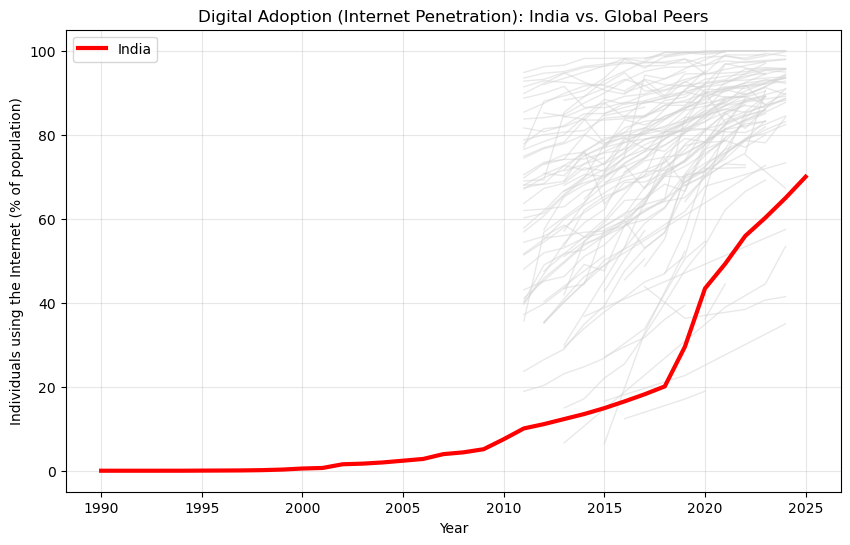

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Load the RAW long data (before the dropna that removed India)
df_long = pd.read_csv("/Users/abhishek/Desktop/world-bank-indicators-project/notebooks/02_digital_adoption/panel_long.csv")

# 2. Filter for India and Internet Penetration
india_data = df_long[(df_long['country'] == 'IND') & (df_long['indicator'] == 'IT.NET.USER.ZS')]

# 3. Plot all other countries (using the cleaned wide panel for the background)
wdi_df = pd.read_csv("/Users/abhishek/Desktop/world-bank-indicators-project/notebooks/02_digital_adoption/panel_window_2011_2024.csv")
plt.figure(figsize=(10, 6))

for country in wdi_df['country'].unique():
    if country != 'IND':
        subset = wdi_df[wdi_df['country'] == country]
        plt.plot(subset['year'], subset['IT.NET.USER.ZS'], color='lightgray', alpha=0.5, linewidth=1)

# 4. Plot India (using the raw long data)
plt.plot(india_data['year'], india_data['value'], color='red', linewidth=3, label='India')

plt.title('Digital Adoption (Internet Penetration): India vs. Global Peers')
plt.xlabel('Year')
plt.ylabel('Individuals using the Internet (% of population)')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)

# 5. Save
os.makedirs("outputs/figures", exist_ok=True)
plt.savefig("outputs/figures/task1_india_diffusion.png", dpi=300, bbox_inches='tight')
plt.show()